# 09 — XGBoost ile Orman Yangını Duyarlılığı

**Veri künyesi:** Eriş (2026), Mendeley Data, doi:10.17632/mjz29dh3g8.1 (CC BY 4.0) · Muğla ili, 2015–2024 yangın kayıtları · temizlik sonrası 6410 nokta · bir satır = bir örnek nokta
**Hedef:** regresyonda yangın duyarlılık skoru (0/1 hedefin olasılık tahmini, `Yangin`), sınıflandırmada `Sinif` (Yangın Yok / Yangın)
**Özellikler (16):** topografya (yükseklik, eğim, bakının sin/cos bileşenleri, düz alan); iklim (yıllık ortalama sıcaklık, aylık ortalama yağış, rüzgâr hızı); bitki örtüsü (NDVI, dört arazi örtüsü göstergesi, referans: orman); insan etkisi (yola, yerleşime ve akarsuya uzaklık)
**Bölünme:** sınıfa göre katmanlı rastgele %80 eğitim / %20 test · güvenilirlik sınaması: eğitim kümesinde 5 katlı sözde mekânsal grup doğrulaması (25 iklim grubu)
**Tekrar üretilebilirlik:** bütün rastgelelikler tek tohuma (`random_state = 42`) bağlıdır; notebook baştan çalıştırıldığında aynı sayılar elde edilir.

XGBoost (eXtreme Gradient Boosting), gradyan artırmanın ikinci dereceden
(Newton) adımlar, düzenlileştirme, paralelleştirme ve eksik veri desteğiyle
güçlendirilmiş mühendislik sürümüdür. Veri bilimi yarışmalarında yaygın biçimde öne
çıkmıştır. scikit-learn ile aynı `fit`/`predict` arayüzünü kullanır; tek farkı sınıf
etiketlerinin sayısal olmasını istemesidir. Model 0,1 öğrenme oranı ve **400** artırma
turuyla (doğrulama kümesiyle seçildi) kurulmuştur.

## 1. Veri Hazırlığı

In [1]:
import ortak as o
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xgboost import XGBRegressor, XGBClassifier
from sklearn.metrics import classification_report

df = o.veri_yukle()
X_tr, X_te, yr_tr, yr_te, yc_tr, yc_te = o.bolunme(df)
yc_tr_k = o.sinif_kodlari(yc_tr)
print(f"Eğitim: {len(X_tr)} nokta  |  Test: {len(X_te)} nokta")
print("Özellikler:", o.OZELLIKLER)
print("Test kümesi sınıf dağılımı:")
print(yc_te.value_counts().reindex(o.SINIF_ETIKETLERI).to_string())

6410 nokta · yangın 3144 · yangın yok 3266
Eğitim: 5128 nokta  |  Test: 1282 nokta
Özellikler: ['Yukseklik', 'Egim', 'Baki_Sin', 'Baki_Cos', 'Baki_Duz', 'Sicaklik', 'Yagis', 'Ruzgar_Hizi', 'NDVI', 'Arazi_Tarim', 'Arazi_Calilik', 'Arazi_Yerlesim', 'Arazi_Su_Ciplak', 'Yol_Uzaklik', 'Yerlesim_Uzaklik', 'Akarsu_Uzaklik']
Test kümesi sınıf dağılımı:
Sinif
Yangın Yok    653
Yangın        629


## 2. Regresyon Görevi: Yangın Duyarlılık Skoru

In [2]:
reg_model = XGBRegressor(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0)
reg_model.fit(X_tr, yr_tr)
y_pred = reg_model.predict(X_te)

reg = o.reg_metrikleri(yr_te, y_pred)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in reg.items():
    print(f"{k:>6}: {v:.4f}")

Test kümesi metrikleri
----------------------------------
   MAE: 0.1391
   MSE: 0.0505
  RMSE: 0.2247
    R2: 0.7979
   AUC: 0.9843


In [3]:
o.reg_grafikleri(yr_te, y_pred, "XGBoost", "xgboost")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\xgboost_regresyon.png'

## 3. Sınıflandırma Görevi: Yangın / Yangın Yok

In [4]:
clf = XGBClassifier(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0)
clf.fit(X_tr, yc_tr_k)
yp = o.koddan_sinifa(clf.predict(X_te))

cls = o.cls_metrikleri(yc_te, yp)
print("Test kümesi metrikleri")
print("-" * 34)
for k, v in cls.items():
    print(f"{k:>14}: {v:.4f}")
print()
print(classification_report(yc_te, yp, labels=o.SINIF_ETIKETLERI, digits=3))

Test kümesi metrikleri
----------------------------------
      Accuracy: 0.9470
   BalancedAcc: 0.9469
      F1_macro: 0.9469
   F1_weighted: 0.9470

              precision    recall  f1-score   support

  Yangın Yok      0.947     0.949     0.948       653
      Yangın      0.947     0.944     0.946       629

    accuracy                          0.947      1282
   macro avg      0.947     0.947     0.947      1282
weighted avg      0.947     0.947     0.947      1282



## 4. Taban Çizgileriyle Karşılaştırma

Her iki görev de iki tür taban çizgisine karşı ölçülür. **Ortalama** ve **çoğunluk**
tabanları hiçbir şey bilmeyen modeldir. **Tek kural** tabanı ise eğitim kümesinden
öğrenilmiş tek bir eşik sorusudur (bir düzeyli karar ağacı): regresyonda kuralın iki
yanındaki yangın oranlarını, sınıflandırmada kuralın iki yanındaki çoğunluk sınıfını
tahmin eder. Asıl geçilmesi gereken çizgi tek kuraldır.

In [5]:
tb = o.taban_cizgileri(df)

print("REGRESYON")
print(f"  {'Ölçüt':>6} | {'model':>8} | {'ortalama':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in reg:
    fark = reg[k] - tb["kural_regresyon"][k]
    yorum = ("iyi" if fark > 0 else "kötü") if k in o.BUYUK_IYI else ("iyi" if fark < 0 else "kötü")
    print(f"  {k:>6} | {reg[k]:8.4f} | {tb['regresyon'][k]:8.4f} | "
          f"{tb['kural_regresyon'][k]:9.4f} | {fark:+.4f} ({yorum})")

print()
print("SINIFLANDIRMA (çoğunluk sınıfı:", tb["cogunluk_sinifi"], ")")
print(f"  {'Ölçüt':>14} | {'model':>7} | {'çoğunluk':>8} | {'tek kural':>9} | tek kurala göre fark")
for k in cls:
    print(f"  {k:>14} | {cls[k]:7.4f} | {tb['siniflandirma'][k]:8.4f} | "
          f"{tb['kural_siniflandirma'][k]:9.4f} | {cls[k] - tb['kural_siniflandirma'][k]:+.4f}")
print(f"Tek kural: {o.OKUNUR[tb['kural']['ozellik']]} ≤ {tb['kural']['esik']:.1f}")

REGRESYON
   Ölçüt |    model | ortalama | tek kural | tek kurala göre fark
     MAE |   0.1391 |   0.4998 |    0.3931 | -0.2539 (iyi)
     MSE |   0.0505 |   0.2499 |    0.1978 | -0.1473 (iyi)
    RMSE |   0.2247 |   0.4999 |    0.4447 | -0.2200 (iyi)
      R2 |   0.7979 |  -0.0000 |    0.2086 | +0.5893 (iyi)
     AUC |   0.9843 |   0.5000 |    0.6982 | +0.2861 (iyi)

SINIFLANDIRMA (çoğunluk sınıfı: Yangın Yok )
           Ölçüt |   model | çoğunluk | tek kural | tek kurala göre fark
        Accuracy |  0.9470 |   0.5094 |    0.6934 | +0.2535
     BalancedAcc |  0.9469 |   0.5000 |    0.6982 | +0.2487
        F1_macro |  0.9469 |   0.3375 |    0.6748 | +0.2721
     F1_weighted |  0.9470 |   0.3438 |    0.6733 | +0.2736
Tek kural: Yükseklik ≤ 1258.0


In [6]:
o.karmasiklik_grafigi(yc_te, yp, "XGBoost", "xgboost")

XGBoost — karmaşıklık matrisi (satır: gerçek, sütun: tahmin)
  sınıf sırası: ['Yangın Yok', 'Yangın']
  Yangın Yok |   620     33
      Yangın |    35    594


'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\xgboost_siniflandirma.png'

## 5. Algoritmaya Özgü Analiz

### Özellik Önemleri ve Artırma Turu Sayısının Etkisi

`n_estimators`, modele eklenen ağaç sayısıdır; yani artırma turu sayısı. Tur sayısı
arttıkça model karmaşıklaşır, ancak bir noktadan sonra kazanç durur ve aşırı öğrenme
riski yükselir. Önemler, XGBoost'un varsayılan ölçütü olan bölünme kazancına (gain)
göre verilmiştir.

In [7]:
o.ozellik_onem_grafigi(clf.feature_importances_, "XGBoost", "xgboost")

'C:\\Users\\BALTRON\\Desktop\\kitapdeprem\\kitapdeprem\\ORMAN YANGINI\\sekiller\\xgboost_onem.png'

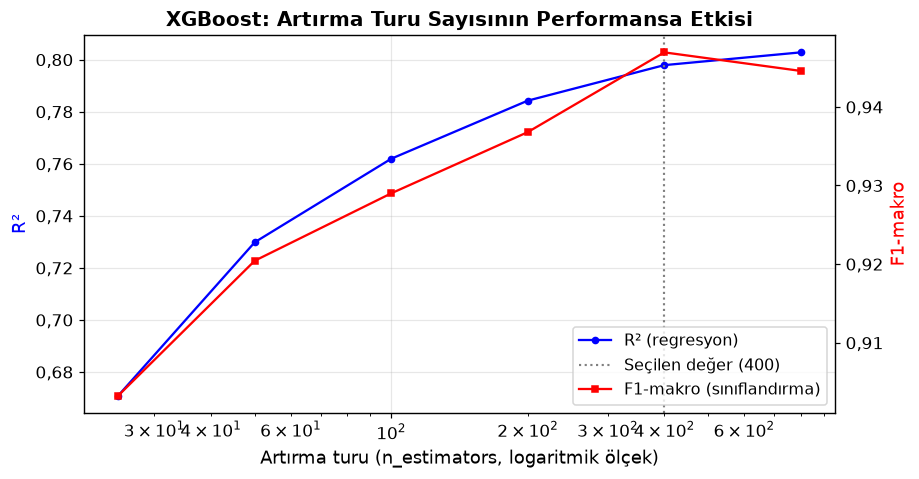

Tarama: [(25, 0.6709, 0.9033), (50, 0.7298, 0.9204), (100, 0.7619, 0.929), (200, 0.7842, 0.9368), (400, 0.7979, 0.9469), (800, 0.8028, 0.9446)]
En yüksek R²: 0.8028 (800) · en yüksek F1-makro: 0.9469 (400)


In [8]:
degerler = [25, 50, 100, 200, 400, 800]
r2_list, f1_list = [], []
for nn in degerler:
    r = XGBRegressor(n_estimators=nn, learning_rate=0.1, random_state=42, verbosity=0).fit(X_tr, yr_tr)
    r2_list.append(o.reg_metrikleri(yr_te, r.predict(X_te))["R2"])
    c = XGBClassifier(n_estimators=nn, learning_rate=0.1, random_state=42, verbosity=0).fit(X_tr, yc_tr_k)
    f1_list.append(o.cls_metrikleri(yc_te, o.koddan_sinifa(c.predict(X_te)))["F1_macro"])
fig, ax1 = plt.subplots(figsize=(8.5, 4.5))
ax1.semilogx(degerler, r2_list, "b-o", ms=4, label="R² (regresyon)")
ax1.axvline(400, color="gray", ls=":", lw=1.4, label="Seçilen değer (400)")
ax1.set_xlabel("Artırma turu (n_estimators, logaritmik ölçek)")
ax1.set_ylabel("R²", color="b")
ax2 = ax1.twinx()
ax2.semilogx(degerler, f1_list, "r-s", ms=4, label="F1-makro (sınıflandırma)")
ax2.set_ylabel("F1-makro", color="r")
ax2.grid(False)
ax1.set_title("XGBoost: Artırma Turu Sayısının Performansa Etkisi")
s1, e1 = ax1.get_legend_handles_labels()
s2, e2 = ax2.get_legend_handles_labels()
ax1.legend(s1 + s2, e1 + e2, loc="lower right")
fig.tight_layout()
fig.savefig(os.path.join(o.SEKIL_DIR, "xgboost_nest_duyarlilik.png"), bbox_inches="tight")
plt.show()
duyarlilik = {"degerler": [float(d) for d in degerler], "R2": [float(v) for v in r2_list],
              "F1_macro": [float(v) for v in f1_list]}
print("Tarama:", [(d, round(r, 4), round(f, 4)) for d, r, f in zip(degerler, r2_list, f1_list)])
print(f"En yüksek R²: {max(r2_list):.4f} ({degerler[int(np.argmax(r2_list))]}) · "
      f"en yüksek F1-makro: {max(f1_list):.4f} ({degerler[int(np.argmax(f1_list))]})")

## Güvenilirlik Sınaması: Sözde Mekânsal Grup Katlamalı Doğrulama

Rastgele bölünmede bir test noktasının hemen yanındaki noktalar eğitimde kalır; bu
noktalar neredeyse aynı iklim, yükseklik ve arazi değerlerini taşıdığı için model test
noktasını "komşusundan ezberleyerek" doğru bilebilir. Veri setinde koordinat olmadığından
konumun yerine iklim yüzeyleri kullanılır: noktalar sıcaklık, yağış ve rüzgâr değerlerine
göre 25 gruba ayrılmıştır ve her grup yaklaşık bir bölgeye karşılık gelir. Aşağıdaki döngü
yalnızca **eğitim kümesini** kullanır ve 5 kat kurar; her katta bazı gruplar **bütünüyle**
dışarıda bırakılır ve model hiç görmediği bu bölgelerde sınanır. Test kümesine bu döngüde
hiç dokunulmaz. Rastgele test sonucu ile bu sınamanın sonucu arasındaki fark, ana
sonuçlardaki iyimserliğin ölçüsüdür.

In [9]:
import numpy as np

cv_r2, cv_f1, cv_yil = [], [], []
for kat, Xa, Xb, yra, yrb, ysa, ysb in o.cv_katlari(df):
    r_tahmin = XGBRegressor(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0).fit(Xa, yra).predict(Xb)
    c_tahmin = o.koddan_sinifa(XGBClassifier(n_estimators=400, learning_rate=0.1, random_state=42, verbosity=0).fit(Xa, o.sinif_kodlari(ysa)).predict(Xb))
    cv_r2.append(o.reg_metrikleri(yrb, r_tahmin)["R2"])
    cv_f1.append(o.cls_metrikleri(ysb, c_tahmin)["F1_macro"])
    cv_yil.append(kat)
    print(f"  kat {kat}: eğitim {len(Xa):5d} · sınama {len(Xb):5d}"
          f" · R² {cv_r2[-1]:+.4f} · F1-makro {cv_f1[-1]:.4f}")

cv_r2, cv_f1 = np.array(cv_r2, dtype=float), np.array(cv_f1, dtype=float)
print("Sözde mekânsal grup doğrulaması (5 kat)")
print(f"  R²      : {np.nanmean(cv_r2):+.4f} ± {np.nanstd(cv_r2):.4f}")
print(f"  F1-makro: {np.nanmean(cv_f1):.4f} ± {np.nanstd(cv_f1):.4f}")
cv_ozet = {"katlar": cv_yil, "R2": [None if np.isnan(v) else float(v) for v in cv_r2],
           "F1_macro": [None if np.isnan(v) else float(v) for v in cv_f1],
           "R2_ort": None if np.all(np.isnan(cv_r2)) else float(np.nanmean(cv_r2)),
           "R2_std": None if np.all(np.isnan(cv_r2)) else float(np.nanstd(cv_r2)),
           "F1_ort": None if np.all(np.isnan(cv_f1)) else float(np.nanmean(cv_f1)),
           "F1_std": None if np.all(np.isnan(cv_f1)) else float(np.nanstd(cv_f1))}


  kat 1: eğitim  4023 · sınama  1105 · R² -0.0008 · F1-makro 0.7393


  kat 2: eğitim  4170 · sınama   958 · R² +0.0714 · F1-makro 0.6465


  kat 3: eğitim  4114 · sınama  1014 · R² +0.5232 · F1-makro 0.8521


  kat 4: eğitim  4055 · sınama  1073 · R² +0.3657 · F1-makro 0.8389


  kat 5: eğitim  4150 · sınama   978 · R² +0.4491 · F1-makro 0.8301
Sözde mekânsal grup doğrulaması (5 kat)
  R²      : +0.2817 ± 0.2085
  F1-makro: 0.7814 ± 0.0783


In [10]:
o.sonuc_kaydet("xgboost", reg, cls, ek={"cv": cv_ozet, "duyarlilik": duyarlilik, "tahmin_reg": np.round(y_pred, 3).tolist(), "tahmin_sinif": [str(v) for v in yp]})

Sonuçlar kaydedildi: C:\Users\BALTRON\Desktop\kitapdeprem\kitapdeprem\ORMAN YANGINI\sonuclar\xgboost.json


{'algoritma': 'xgboost',
 'regresyon': {'MAE': 0.1391139829859309,
  'MSE': 0.05051228927229973,
  'RMSE': 0.22474939215112402,
  'R2': 0.7978800066369303,
  'AUC': 0.9843208671242182},
 'siniflandirma': {'Accuracy': 0.9469578783151326,
  'BalancedAcc': 0.9469100665389287,
  'F1_macro': 0.9469360525136836,
  'F1_weighted': 0.9469561994073289},
 'ek': {'cv': {'katlar': [1, 2, 3, 4, 5],
   'R2': [-0.0007573383556465085,
    0.07144783846632197,
    0.5232155074839451,
    0.3657061907290744,
    0.44913156934431986],
   'F1_macro': [0.7393304370048557,
    0.6464710938016505,
    0.8521079291247019,
    0.8389147633245586,
    0.830126608768442],
   'R2_ort': 0.28174875353360296,
   'R2_std': 0.20852252558663478,
   'F1_ort': 0.7813901664048417,
   'F1_std': 0.07830389392417739},
  'duyarlilik': {'degerler': [25.0, 50.0, 100.0, 200.0, 400.0, 800.0],
   'R2': [0.6709352611127044,
    0.729844117972045,
    0.7619254873680562,
    0.7842375177817398,
    0.7978800066369303,
    0.802786548